# Load the example data

Two anonymized on-task recordings: Pursuit and Rotations. Run this notebook from `examples/`.

Each `.npz` file holds named NumPy arrays. `spike_counts` has time bins as rows and units as columns; each bin is 100 ms. See [README.md](README.md) for the other fields.

In [1]:
import numpy as np

pursuit = np.load("data_for_reviewers/example_pursuit.npz")
rotations = np.load("data_for_reviewers/example_rotations.npz")

Both files have the same fields. Access an array by its name, for example `pursuit["spike_counts"]`. Matching `unit_ids` identify the same unit across tasks.

In [2]:
print(pursuit.files)

['spike_counts', 'unit_ids', 'regions', 'full_session_mean_rate_hz']


In [3]:
print("Pursuit (bins, units):", pursuit["spike_counts"].shape)
print("Rotations (bins, units):", rotations["spike_counts"].shape)

Pursuit (bins, units): (13981, 33)
Rotations (bins, units): (7401, 39)


## Task A/B decoding — Fig. 2I

Decode Pursuit versus Rotations from the 33 matched HPC/ACC units. Match columns by `unit_ids`, then convert the 100 ms spike counts to firing rates.

As in Fig. 2I, use logistic regression with standardization fitted separately inside each training fold. This example uses 10 shuffled stratified folds with seed 0 and prints the mean held-out ROC AUC. The score measures task discrimination within these two recordings.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

shared_units, pursuit_idx, rotations_idx = np.intersect1d(
    pursuit["unit_ids"], rotations["unit_ids"], return_indices=True
)
# Convert counts in 100 ms bins to Hz.
X_pursuit = pursuit["spike_counts"][:, pursuit_idx] * 10.0
X_rotations = rotations["spike_counts"][:, rotations_idx] * 10.0
X = np.vstack([X_pursuit, X_rotations])
y = np.r_[np.zeros(len(X_pursuit)), np.ones(len(X_rotations))]

In [5]:
decoder = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="liblinear", random_state=0),
)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
auc = cross_val_score(decoder, X, y, cv=cv, scoring="roc_auc")
print(f"Pursuit vs Rotations: mean ROC AUC = {auc.mean():.4f}")

Pursuit vs Rotations: mean ROC AUC = 0.9690


## Factor analysis — Fig. 3B and 3F

Use all selected units in each task: 33 in Pursuit and 39 in Rotations. Normalize each unit within its task, then fit FA with the existing `normalize` and `FAResults` helpers. Shared dimensionality is the number of factors needed to explain at least 95% of the shared variance. These example fits characterize each task separately.

In [6]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))  # Import helpers from the repository root.
from data_loader import normalize
from decomposition import FAResults
from utils import TASK_CLR, fig_set, finish_plot

fig_set()
SAVEFIG = False  # Set True to also save the figures in examples/plots/.

rates_pursuit = pursuit["spike_counts"] * 10.0
rates_rotations = rotations["spike_counts"] * 10.0
fa_pursuit = FAResults().fa_fit(normalize(rates_pursuit))
fa_rotations = FAResults().fa_fit(normalize(rates_rotations))
max_units = max(rates_pursuit.shape[1], rates_rotations.shape[1])

print(f"Pursuit: shared dimensions = {fa_pursuit.d_shared}; units = {rates_pursuit.shape[1]}")
print(f"Rotations: shared dimensions = {fa_rotations.d_shared}; units = {rates_rotations.shape[1]}")

Pursuit: shared dimensions = 9; units = 33
Rotations: shared dimensions = 10; units = 39


### Cumulative shared variance explained — Fig. 3B

The dashed lines mark the 95% threshold and the corresponding shared dimensionality. Factor dimensions are numbered starting at 1.

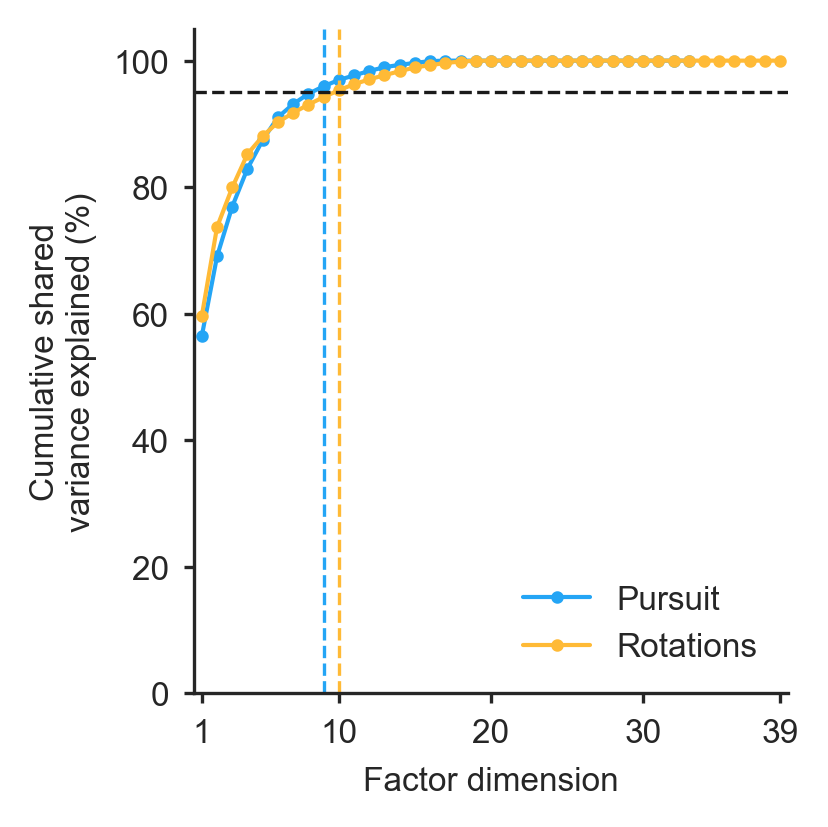

In [7]:
plt.figure(figsize=(2.8, 2.8), dpi=300)
for task, fa in [("pursuit", fa_pursuit), ("rotations", fa_rotations)]:
    dimensions = np.arange(1, len(fa.explained_variance_ratio_) + 1)
    cumulative = np.cumsum(fa.explained_variance_ratio_) * 100
    plt.plot(dimensions, cumulative, "o-", markersize=2,
             color=TASK_CLR[task], label=task.capitalize())
    plt.axvline(fa.d_shared, ls="--", lw=0.8, color=TASK_CLR[task])

plt.axhline(95, ls="--", lw=0.8, color="k")
plt.xlabel("Factor dimension")
plt.ylabel("Cumulative shared\nvariance explained (%)")
plt.ylim(0, 105)
plt.xlim(0.5, max_units + 0.5)
plt.xticks([1, 10, 20, 30, max_units])
plt.legend(frameon=False)
finish_plot(filename="cumulative_shared_variance", save_dir="plots", savefig=SAVEFIG)

### Shared variance per unit — Fig. 3F

Plot the percentage of each unit's modeled variance attributed to shared activity, using `FAResults.shared_var_per_unit`. Sort each task's units independently by shared variance. The x-axis is rank within that task.

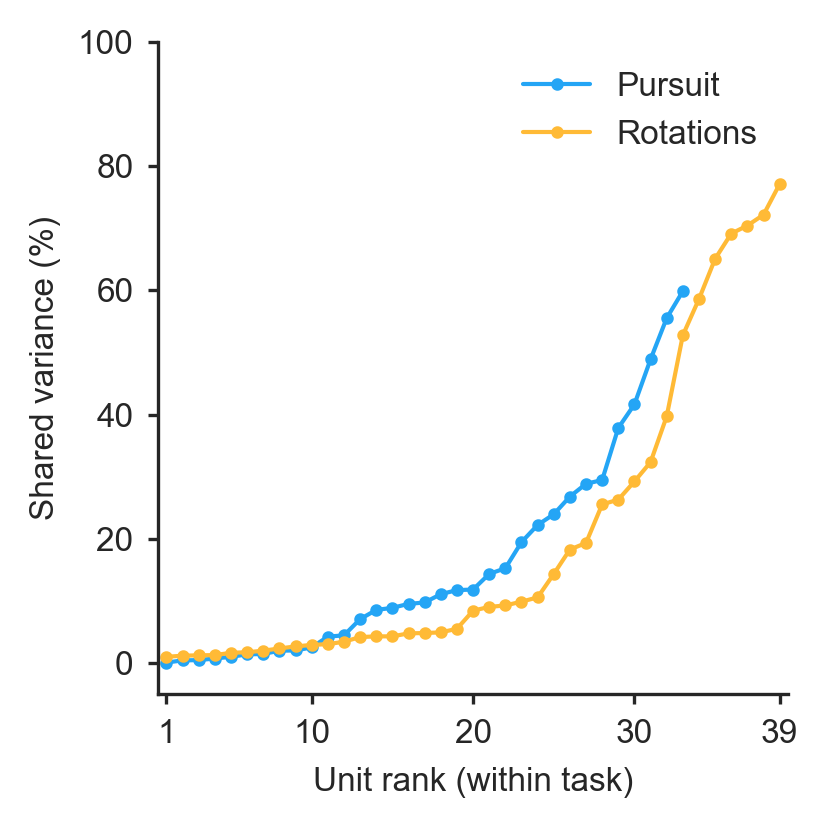

In [8]:
plt.figure(figsize=(2.8, 2.8), dpi=300)
for task, fa in [("pursuit", fa_pursuit), ("rotations", fa_rotations)]:
    shared_variance = np.sort(fa.shared_var_per_unit) * 100
    unit_numbers = np.arange(1, len(shared_variance) + 1)
    plt.plot(unit_numbers, shared_variance, "o-", markersize=2,
             color=TASK_CLR[task], label=task.capitalize())

plt.xlabel("Unit rank (within task)")
plt.ylabel("Shared variance (%)")
plt.ylim(-5, 100)
plt.xlim(0.5, max_units + 0.5)
plt.xticks([1, 10, 20, 30, max_units])
plt.legend(frameon=False)
finish_plot(filename="shared_variance_per_unit", save_dir="plots", savefig=SAVEFIG)

## Regional comparisons — Fig. 4A–B

Use all selected units in each session: 26 HPC and 7 ACC units in Pursuit, and 31 HPC and 8 ACC units in Rotations. As in `regions.py`, shared variance comes from FA fitted to normalized on-task activity, while firing rates are the supplied full-session mean rates. Histograms show each region separately within each task; printed summaries give the median and interquartile range (IQR).

In [9]:
from utils import AREA_CLR

regional_data = {"pursuit": pursuit, "rotations": rotations}
regional_rates = {"pursuit": rates_pursuit, "rotations": rates_rotations}
regional_fa = {"pursuit": fa_pursuit, "rotations": fa_rotations}

for task, data in regional_data.items():
    for region in ["HPC", "ACC"]:
        selected = data["regions"] == region
        shared = regional_fa[task].shared_var_per_unit[selected] * 100
        rates = data["full_session_mean_rate_hz"][selected]
        sv_q1, sv_median, sv_q3 = np.percentile(shared, [25, 50, 75])
        fr_q1, fr_median, fr_q3 = np.percentile(rates, [25, 50, 75])
        print(f"{task.capitalize()} {region} (n={selected.sum()}): "
              f"shared variance {sv_median:.1f}% (IQR {sv_q1:.1f}–{sv_q3:.1f}%); "
              f"firing rate {fr_median:.2f} Hz (IQR {fr_q1:.2f}–{fr_q3:.2f})")

Pursuit HPC (n=26): shared variance 13.1% (IQR 4.0–28.4%); firing rate 2.89 Hz (IQR 1.51–11.26)
Pursuit ACC (n=7): shared variance 4.3% (IQR 1.2–5.8%); firing rate 1.84 Hz (IQR 0.69–2.20)
Rotations HPC (n=31): shared variance 10.6% (IQR 4.8–36.0%); firing rate 4.35 Hz (IQR 0.70–13.65)
Rotations ACC (n=8): shared variance 2.5% (IQR 1.8–3.1%); firing rate 0.90 Hz (IQR 0.68–1.35)


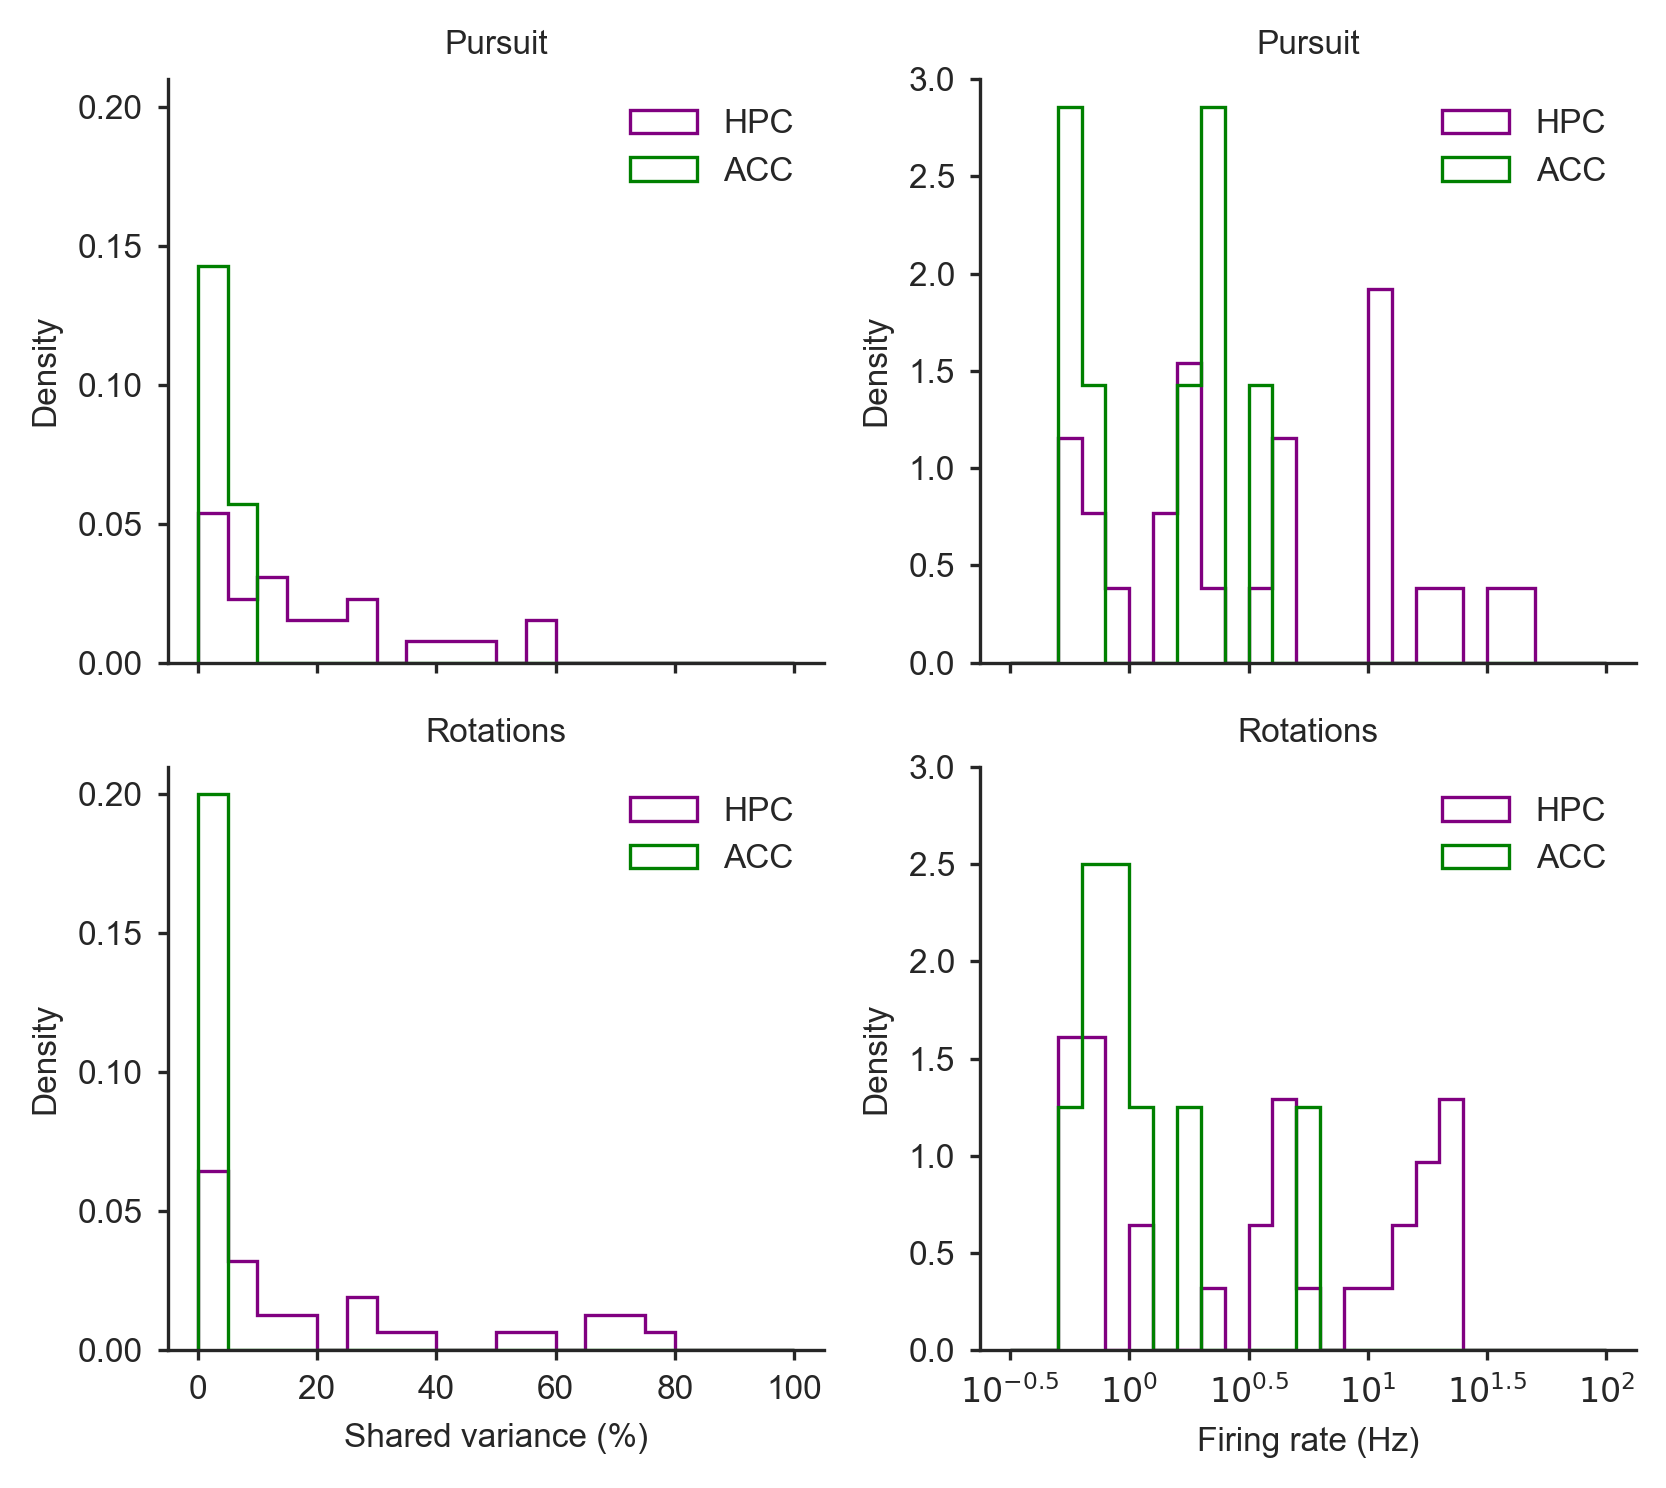

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(5.6, 5.0), dpi=300, sharex="col", sharey="col")
for row, (task, data) in enumerate(regional_data.items()):
    for region in ["HPC", "ACC"]:
        selected = data["regions"] == region
        shared = regional_fa[task].shared_var_per_unit[selected] * 100
        log_rates = np.log10(data["full_session_mean_rate_hz"][selected])
        axes[row, 0].hist(shared, bins=np.linspace(0, 100, 21), density=True,
                          histtype="step", color=AREA_CLR[region], lw=0.8, label=region)
        axes[row, 1].hist(log_rates, bins=np.linspace(-0.5, 2, 26), density=True,
                          histtype="step", color=AREA_CLR[region], lw=0.8, label=region)
    for ax in axes[row]:
        ax.set_title(task.capitalize())
        ax.set_ylabel("Density")
        ax.legend(frameon=False)

axes[-1, 0].set_xlabel("Shared variance (%)")
axes[-1, 1].set_xlabel("Firing rate (Hz)")
axes[-1, 1].set_xticks([-0.5, 0, 0.5, 1, 1.5, 2],
                       [r"$10^{-0.5}$", r"$10^0$", r"$10^{0.5}$", r"$10^1$", r"$10^{1.5}$", r"$10^2$"])
finish_plot(filename="regional_shared_variance_and_rates", save_dir="plots", savefig=SAVEFIG)

### HPC contribution — Fig. 4D

Balance the number of HPC and ACC units before fitting FA, using ten resamples with seeds 0–9 as in `Session.resample_y`. Each draw uses 7 units per region for Pursuit or 8 per region for Rotations. For each shared dimension, HPC contribution is the sum of squared orthonormal loadings over HPC units. A contribution of 0.5 represents equal HPC and ACC contributions. The two histograms use identical bins and axes; repeated resamples are not independent observations.

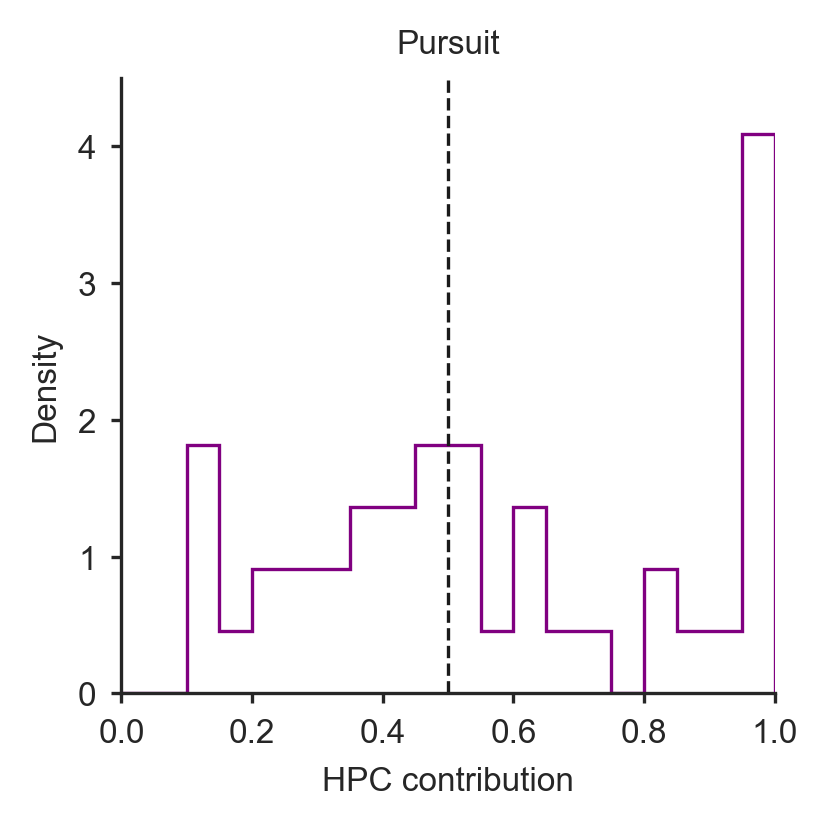

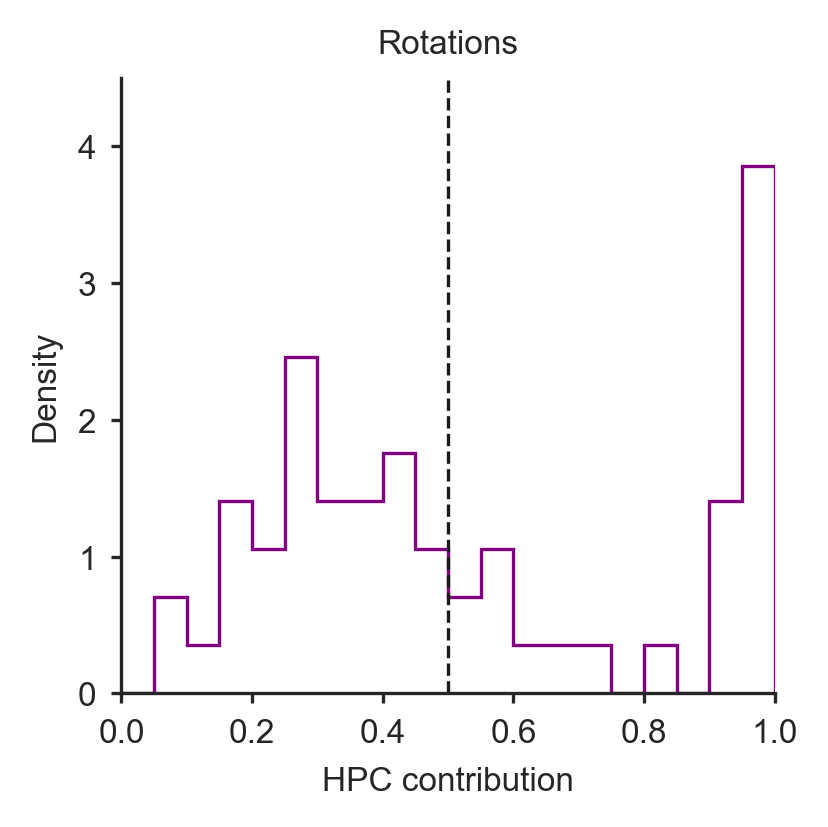

In [11]:
hpc_contributions = {}
for task, data in regional_data.items():
    hpc_indices = np.flatnonzero(data["regions"] == "HPC")
    acc_indices = np.flatnonzero(data["regions"] == "ACC")
    n_per_region = min(len(hpc_indices), len(acc_indices))
    contributions = []
    for seed in range(10):
        rng = np.random.default_rng(seed)
        hpc_selected = np.sort(rng.choice(hpc_indices, n_per_region, replace=False))
        acc_selected = np.sort(rng.choice(acc_indices, n_per_region, replace=False))
        selected = np.r_[hpc_selected, acc_selected]  # HPC columns come first.
        fa_balanced = FAResults().fa_fit(
            normalize(regional_rates[task][:, selected]), shared_var_thresh=0.95, max_iter=10000
        )
        contributions.extend((fa_balanced.subspace[:, :n_per_region] ** 2).sum(axis=1))
    hpc_contributions[task] = np.asarray(contributions)

contribution_bins = np.linspace(0, 1, 21)
max_density = max(np.histogram(values, bins=contribution_bins, density=True)[0].max()
                  for values in hpc_contributions.values())
for task, values in hpc_contributions.items():
    plt.figure(figsize=(2.8, 2.8), dpi=300)
    plt.hist(values, bins=contribution_bins, density=True,
             histtype="step", color=AREA_CLR["HPC"], lw=0.8)
    plt.axvline(0.5, ls="--", color="k", lw=0.8)
    plt.xlim(0, 1)
    plt.ylim(0, max_density * 1.1)
    plt.xlabel("HPC contribution")
    plt.ylabel("Density")
    plt.title(task.capitalize())
    finish_plot(filename=f"hpc_contribution_{task}", save_dir="plots", savefig=SAVEFIG)

### Units exceeding the shifted threshold — Fig. 4F

Use the supplied numerical outputs from the original regional FA and 200 HPC-shift controls per task. All HPC units were circularly shifted together relative to ACC along the retained on-task bins, with a minimum shift of 10 seconds in either circular direction. Only converged fits enter the calculation.

For each unit, compute the change in shared variance between the joint model and its region-only model. Following `collect_delta_svpu_per_region` in `regions.py`, the empirical p-value is the fraction of shifted changes strictly greater than the real change. Print the percentage of units with p < 0.05 separately for HPC and ACC. These control fits use the original CV-selected ranks recorded in the files (joint ranks: Pursuit 19, Rotations 14); the notebook calculates the percentages from saved results.

In [12]:
shift_pvalues = {}
for task, data in regional_data.items():
    with np.load(f"data_for_reviewers/example_{task}_shifts.npz") as results:
        assert np.array_equal(results["unit_ids"], data["unit_ids"])
        converged = results["shift_converged"]
        alone = results["region_only_shared_var_per_unit"]
        real_delta = 100 * (results["joint_shared_var_per_unit"] - alone)
        shifted_delta = 100 * (results["shifted_shared_var_per_unit"][converged] - alone)
        p_values = (shifted_delta > real_delta[None, :]).mean(axis=0)
        shift_pvalues[task] = p_values
        print(f"{task.capitalize()} ({converged.sum()}/{int(results['n_shifts_planned'])} converged HPC shifts):")
        for region in ["HPC", "ACC"]:
            selected = data["regions"] == region
            n_pass = np.count_nonzero(p_values[selected] < 0.05)
            n_units = selected.sum()
            print(f"  {region}: {100 * n_pass / n_units:.1f}% ({n_pass}/{n_units} units)")

Pursuit (200/200 converged HPC shifts):
  HPC: 11.5% (3/26 units)
  ACC: 0.0% (0/7 units)
Rotations (200/200 converged HPC shifts):
  HPC: 9.7% (3/31 units)
  ACC: 0.0% (0/8 units)


## Principal angles — Fig. 5

Compare the two task subspaces using their 33 shared units in the same column order. Refit FA on these matched populations with the original Fig. 5 settings, then compute principal angles using `principal_angles`. The retained ranks are 9 for Pursuit and 8 for Rotations, giving eight principal angles.

The supplied control file contains only this task pair: 500 random comparisons and 500 within-task shuffled comparisons from each task. The shuffled control compares subspaces estimated from two random halves of the same task's population time bins, retaining the observed rank pair. Both tasks' shuffled controls are pooled, as in the manuscript plot. Gray bands show mean ± one standard deviation.

In [13]:
from utils import principal_angles, TASK_PAIRS_CLR

angle_results = np.load("data_for_reviewers/example_principal_angles.npz")
pa_fits = []
for data in [pursuit, rotations]:
    columns = [np.flatnonzero(data["unit_ids"] == unit)[0] for unit in angle_results["unit_ids"]]
    rates = data["spike_counts"][:, columns] * 10.0
    fa = FAResults().fa_fit(
        normalize(rates), shared_var_thresh=float(angle_results["shared_var_thresh"]),
        max_iter=int(angle_results["fa_max_iter"]), tol=float(angle_results["fa_tol"]),
        svd_method="lapack",
    )
    pa_fits.append(fa)

angles = principal_angles(pa_fits[0].subspace.T, pa_fits[1].subspace.T)
np.testing.assert_allclose(angles, angle_results["data_pa"], rtol=0, atol=1e-8)
random_angles = angle_results["rand_pa"]
shuffled_angles = np.concatenate([angle_results["shuf_task1_pa"], angle_results["shuf_task2_pa"]])

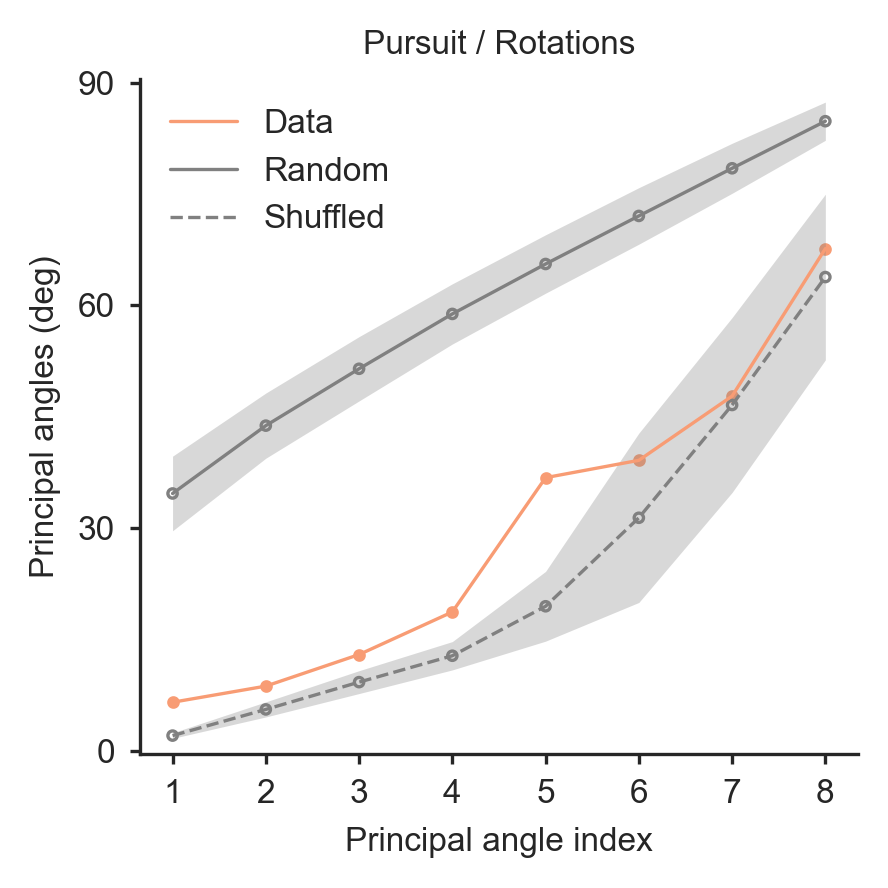

In [14]:
fig, ax = plt.subplots(figsize=(3, 3), dpi=300)
angle_indices = np.arange(1, len(angles) + 1)
color = TASK_PAIRS_CLR["RS"]
ax.scatter(angle_indices, angles, color=color, s=5, lw=0.8)
ax.plot(angle_indices, angles, color=color, lw=0.8, label="Data")
for values, label, linestyle in [(random_angles, "Random", "-"),
                                 (shuffled_angles, "Shuffled", "--")]:
    mean, std = values.mean(axis=0), values.std(axis=0)
    ax.scatter(angle_indices, mean, edgecolors="gray", facecolors="none", s=5, lw=0.8)
    ax.plot(angle_indices, mean, color="gray", ls=linestyle, lw=0.8, label=label)
    ax.fill_between(angle_indices, mean - std, mean + std, color="gray", alpha=0.3, lw=0)
ax.set(ylim=(-0.5, 90.5), yticks=np.linspace(0, 90, 4), xticks=angle_indices,
       xlabel="Principal angle index", ylabel="Principal angles (deg)", title="Pursuit / Rotations")
ax.legend(frameon=False)
finish_plot(filename="principal_angles", save_dir="plots", savefig=SAVEFIG)

### More-aligned subspace distance — Fig. 5C

Use the smallest half of the principal angles: the first four of eight. As in `geodesic_summary(style="more")`, distance is the Euclidean norm of these angles in degrees. Control distances are computed for each repeat before reporting their mean and standard deviation.

In [15]:
n_more_aligned = len(angles) // 2
more_aligned_distance = np.linalg.norm(angles[:n_more_aligned])
random_distances = np.linalg.norm(random_angles[:, :n_more_aligned], axis=1)
shuffled_distances = np.linalg.norm(shuffled_angles[:, :n_more_aligned], axis=1)

print(f"More-aligned dimensions: {n_more_aligned}")
print(f"Data subspace distance: {more_aligned_distance:.2f}°")
print(f"Shuffled: {shuffled_distances.mean():.2f} ± {shuffled_distances.std():.2f}° (mean ± SD)")
print(f"Random: {random_distances.mean():.2f} ± {random_distances.std():.2f}° (mean ± SD)")

More-aligned dimensions: 4
Data subspace distance: 25.19°
Shuffled: 16.93 ± 2.01° (mean ± SD)
Random: 96.25 ± 6.66° (mean ± SD)


## Proportional variance explained — Fig. 6C

Use the matched-unit FA fits from Fig. 5. Each category contains four dimensions: the top FA factors, the more-aligned principal directions, or the less-aligned principal directions. As in `calc_var_exp`, divide each category's projected activity variance by the total projected variance across that task's entire retained subspace (9 dimensions for Pursuit and 8 for Rotations). Print the three proportions for each task.

In [16]:
_, U, Vh = principal_angles(pa_fits[0].subspace.T, pa_fits[1].subspace.T, return_vectors=True)
Q_pursuit, _ = np.linalg.qr(pa_fits[0].subspace.T)
Q_rotations, _ = np.linalg.qr(pa_fits[1].subspace.T)
principal_directions = [Q_pursuit @ U, Q_rotations @ Vh.T]
n_per_group = len(angles) // 2

variance_fractions = {}
print(f"{'Task':<12} {'Top factors':>12} {'More aligned':>14} {'Less aligned':>14}")
for task, fa, directions in zip(["pursuit", "rotations"], pa_fits, principal_directions):
    factor_variance = np.var(fa.data @ fa.subspace.T, axis=0)
    principal_variance = np.var(fa.data @ directions, axis=0)
    total_variance = factor_variance.sum()
    fractions = np.array([
        factor_variance[:n_per_group].sum(),
        principal_variance[:n_per_group].sum(),
        principal_variance[n_per_group:2 * n_per_group].sum(),
    ]) / total_variance
    variance_fractions[task] = fractions  # Top factors, more aligned, less aligned.
    print(f"{task.capitalize():<12} {fractions[0]:12.4f} {fractions[1]:14.4f} {fractions[2]:14.4f}")

Task          Top factors   More aligned   Less aligned
Pursuit            0.6083         0.5847         0.3326
Rotations          0.6974         0.6904         0.3096


## Paired mean firing rates — Fig. S6C

For each of the 33 matched units, average its firing rate over the retained on-task bins. Plot log10 mean firing rate as a boxplot with overlaid points, connecting the same unit across Pursuit and Rotations. The boxes show the median and interquartile range; whiskers span the 5th–95th percentiles. Each pair shares one horizontal jitter offset so lines meet their points.

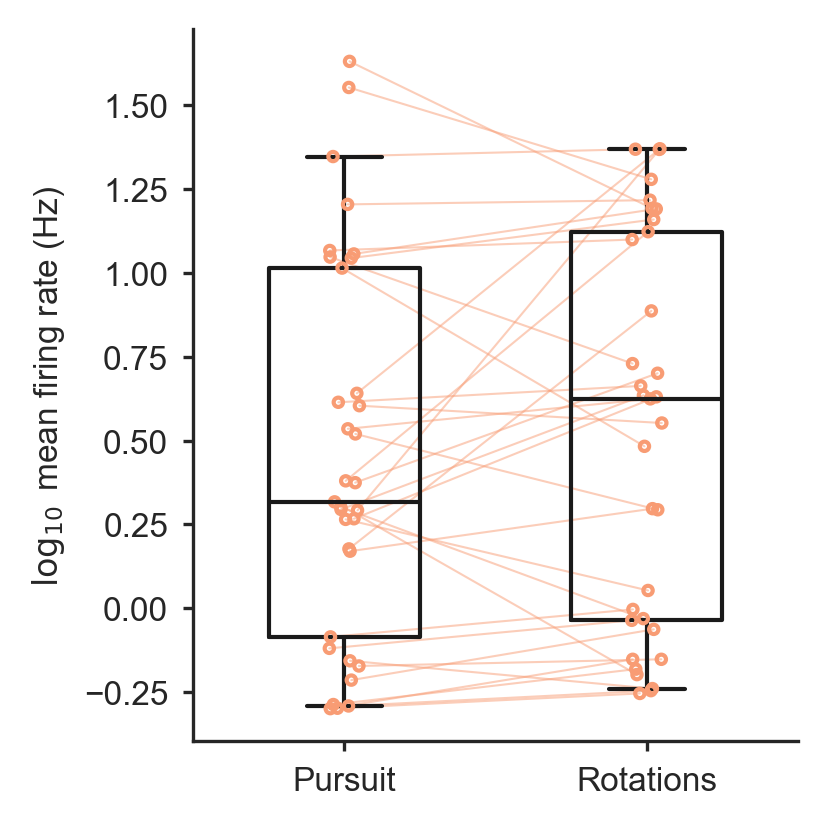

In [17]:
import seaborn as sns

paired_mean_rates = np.column_stack([X_pursuit.mean(axis=0), X_rotations.mean(axis=0)])
log_mean_rates = np.log10(paired_mean_rates)

fig, ax = plt.subplots(figsize=(2.8, 2.8), dpi=300)
sns.boxplot(data=log_mean_rates, ax=ax, width=0.5, fill=False, color="k",
            whis=(5, 95), showfliers=False)
jitter_offsets = np.random.default_rng(0).uniform(-0.05, 0.05, len(log_mean_rates))
for values, jitter in zip(log_mean_rates, jitter_offsets):
    paired_x = np.array([0, 1]) + jitter
    ax.plot(paired_x, values, color=TASK_PAIRS_CLR["RS"], lw=0.5, alpha=0.5, zorder=1)
    ax.scatter(paired_x, values, facecolors="none", edgecolors=TASK_PAIRS_CLR["RS"],
               linewidths=1, s=5, zorder=2)
ax.set(xticks=[0, 1], xticklabels=["Pursuit", "Rotations"], xlim=(-0.5, 1.5),
       xlabel="", ylabel=r"$\log_{10}$ mean firing rate (Hz)")
finish_plot(filename="paired_mean_firing_rates", save_dir="plots", savefig=SAVEFIG)

## Shared dimensionality by two methods — Fig. S7

Print the CV and 95% threshold dimensions for each example session using the saved **200 ms** results from Fig. S7. The CV estimate maximizes saved mean held-out log-likelihood; the threshold estimate is the number of factors needed to explain at least 95% of shared variance. Both methods use all selected units in each session.

In [18]:
print(f"{'Task':<12} {'CV':>7} {'95% threshold':>15}")
for task in ["pursuit", "rotations"]:
    with np.load(f"data_for_reviewers/example_{task}_dimensionality.npz") as result:
        d_cv = int(result["cv_components"][np.argmax(result["cv_scores"])])
        d_threshold = np.searchsorted(np.cumsum(result["explained_variance_ratio"]),
                                      float(result["shared_var_thresh"])) + 1
        print(f"{task.capitalize():<12} {d_cv:7d} {d_threshold:15d}")

Task              CV   95% threshold
Pursuit           20              10
Rotations          6              11
